In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA = Path("C:/Users/Baxe/Documents/Uni/Socialgraphs/Project/Politics-Network/data")

# Indlæs afstemninger og individuelle stemmer
bills = pd.read_csv(DATA / "processed/afstemninger_2022_2026.csv")
votes = pd.read_csv(DATA / "processed/stemmer_2022_2026.csv")

# Identificér afstemninger, der indgår i analysen
valid_votes = votes.loc[
    (votes["sagstype"] == "Lovforslag") &
    (votes["afstemningstype"] == "Endelig vedtagelse") &
    (votes["stemme"].isin(["For", "Imod"])),
    "afstemning_id"
].unique()

# Afgræns populationen til unikke lovforslag
population = (
    bills[bills["afstemning_id"].isin(valid_votes)]
    .drop_duplicates("sag_id")
    .copy()
)

# Fordeling af lovforslag på emnekategorier
category_counts = population["emne"].value_counts()

# Stikprøvestørrelse og minimum pr. kategori
sample_size = 120
min_per_category = 5

# Fordel stikprøven med mindst fem observationer pr. kategori
allocation = pd.Series(
    min_per_category,
    index=category_counts.index
).clip(upper=category_counts)

# Fordel resterende observationer proportionalt
while allocation.sum() < sample_size:
    remaining = category_counts - allocation
    priority = remaining / (allocation + 1)
    allocation.loc[priority.idxmax()] += 1

# Tilfældig udvælgelse inden for hver kategori
sample = pd.concat([
    population[population["emne"] == category].sample(
        n=int(n),
        random_state=42
    )
    for category, n in allocation.items()
])

# Beregn samplingvægte
sample["sampling_weight"] = sample["emne"].map(
    category_counts / allocation
)

# Bland rækkefølgen, så kategorierne ikke står samlet
sample = sample.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Opret unikt validerings-ID
sample["validation_id"] = range(1, len(sample) + 1)

# Gem algoritmens klassifikation separat
validation_key = sample[
    ["validation_id", "sag_id", "emne", "sampling_weight"]
].rename(columns={"emne": "predicted_topic"})

# Opret datasæt til blind annotering
validation = sample[
    ["validation_id", "sag_id", "samling",
     "sag_nummer", "titel", "resume"]
].copy()

validation["llm_topic"] = ""
validation["manual_topic"] = ""
validation["comment"] = ""

# Mappe til valideringsfiler
OUTPUT = Path("C:/Users/Baxe/Documents/Uni/Socialgraphs/Project/Politics-Network/notebooks/HvadStemmerDe")

# Gem begge filer
validation.to_csv(
    OUTPUT / "manual_validation_bills.csv",
    index=False,
    encoding="utf-8-sig"
)

validation_key.to_csv(
    OUTPUT / "bill_validation_key.csv",
    index=False,
    encoding="utf-8-sig"
)

# Kontrollér stikprøvens fordeling
print("Population:", len(population))
print("Sample:", len(validation))
print("Missing summaries:", validation["resume"].isna().sum())

display(pd.DataFrame({
    "Population": category_counts,
    "Sample": allocation,
    "Sampling weight": category_counts / allocation
}))

Population: 612
Sample: 120
Missing summaries: 1


,Population,Sample,Sampling weight
emne,,,
"Økonomi, skat & energipriser",90,15,6.000000
"Klima, miljø & landbrug",64,11,5.818182
"Erhverv, finans & digitalisering",64,10,6.400000
Sundhed & psykiatri,60,10,6.000000
Ældre & velfærd,52,8,6.500000
Retsvæsen & politi,48,8,6.000000
Uddannelse & forskning,47,8,5.875000
Udlændinge & integration,31,5,6.200000
Beskæftigelse & arbejdsmarked,27,5,5.400000


In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix
)

# Indlæs manuelt validerede lovforslag
annotated = pd.read_csv(
    OUTPUT / "manual_validation_bills_sdn.csv",
    sep=";",
    encoding="utf-8-sig"
)

# Tilpas kolonnenavne
annotated.columns = annotated.columns.str.strip()
annotated = annotated.rename(columns={"manuel": "manual_topic"})

# Indlæs algoritmens oprindelige klassifikation
validation_key = pd.read_csv(
    OUTPUT / "bill_validation_key.csv"
)

# Sammenkobl manuel og automatisk klassifikation
results = annotated.merge(
    validation_key,
    on=["validation_id", "sag_id"],
    how="inner",
    validate="one_to_one"
)

# Fjern eventuelle overflødige mellemrum
results["manual_topic"] = results["manual_topic"].str.strip()
results["predicted_topic"] = results["predicted_topic"].str.strip()

# Kontrollér at alle lovforslag er manuelt annoteret
assert len(results) == 120, "Der mangler lovforslag"
assert results["manual_topic"].notna().all(), "Der mangler manuelle labels"
assert results["manual_topic"].ne("").all(), "Der er tomme manuelle labels"

# Definér kategorier
categories = sorted(validation_key["predicted_topic"].unique())

# Kontrollér at alle manuelle labels er gyldige
invalid_labels = set(results["manual_topic"]) - set(categories)
assert not invalid_labels, f"Ukendte kategorier: {invalid_labels}"

# Reference, forudsigelser og samplingvægte
y_true = results["manual_topic"]
y_pred = results["predicted_topic"]
weights = results["sampling_weight"]

# Beregn populationsvægtede valideringsmål
report = classification_report(
    y_true,
    y_pred,
    labels=categories,
    sample_weight=weights,
    output_dict=True,
    zero_division=0
)

summary = pd.DataFrame(report).T

# Tilføj faktiske antal observationer i stikprøven
summary["manual_n"] = y_true.value_counts()
summary["predicted_n"] = y_pred.value_counts()

# Beregn accuracy
sample_accuracy = accuracy_score(y_true, y_pred)

population_accuracy = accuracy_score(
    y_true,
    y_pred,
    sample_weight=weights
)

print(f"Validated bills: {len(results)}")
print(f"Sample accuracy: {sample_accuracy:.3f}")
print(f"Population-weighted accuracy: {population_accuracy:.3f}")

# Vis resultater pr. kategori
display(summary.round(3))

# Beregn confusion matrix
cm = pd.DataFrame(
    confusion_matrix(
        y_true,
        y_pred,
        labels=categories
    ),
    index=categories,
    columns=categories
)


Validated bills: 120
Sample accuracy: 0.658
Population-weighted accuracy: 0.676


,precision,recall,f1-score,support,manual_n,predicted_n
Andet,0.400,1.000,0.571,6.400,2.0,5.0
Beskæftigelse & arbejdsmarked,0.800,0.426,0.556,50.718,10.0,5.0
Bolig,0.400,1.000,0.571,8.400,2.0,5.0
EU & udenrigs,0.200,0.256,0.224,8.600,2.0,5.0
"Erhverv, finans & digitalisering",0.500,0.786,0.611,40.700,7.0,10.0
Forsvar & sikkerhed,1.000,0.583,0.736,20.600,8.0,5.0
Grønland & Færøerne,0.600,0.504,0.548,25.000,5.0,5.0
"Klima, miljø & landbrug",0.818,0.876,0.846,59.764,11.0,11.0
"Kultur, medier & kirke",1.000,0.738,0.849,24.400,6.0,5.0
Land & by,0.200,0.096,0.130,14.618,4.0,5.0


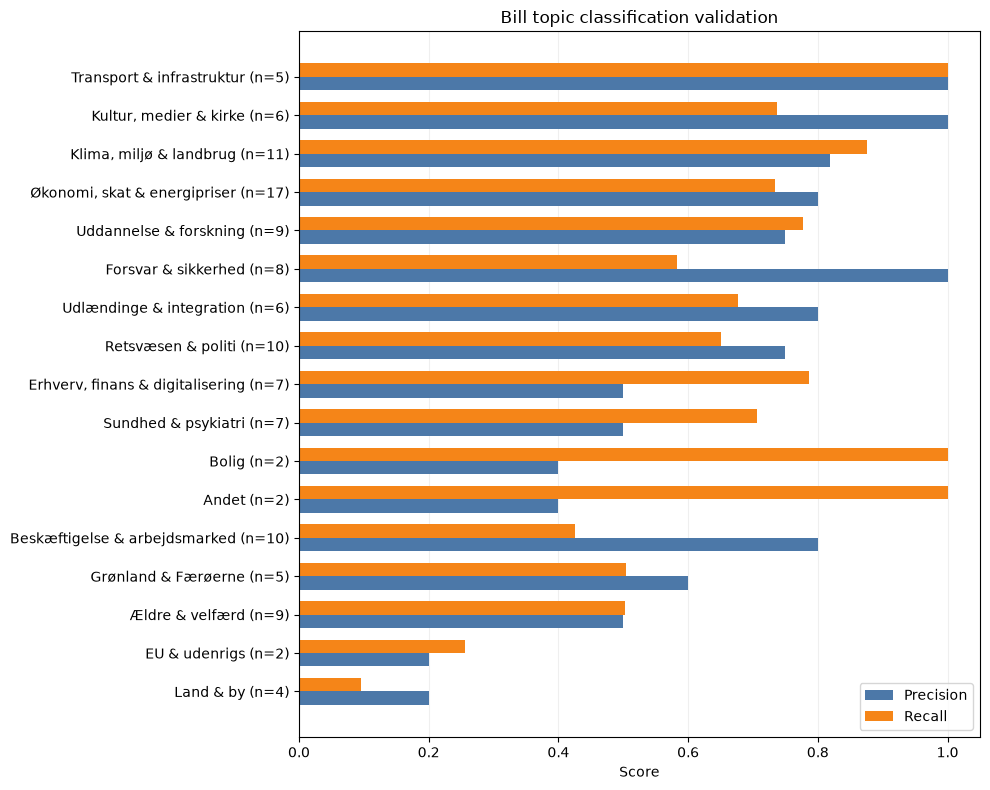

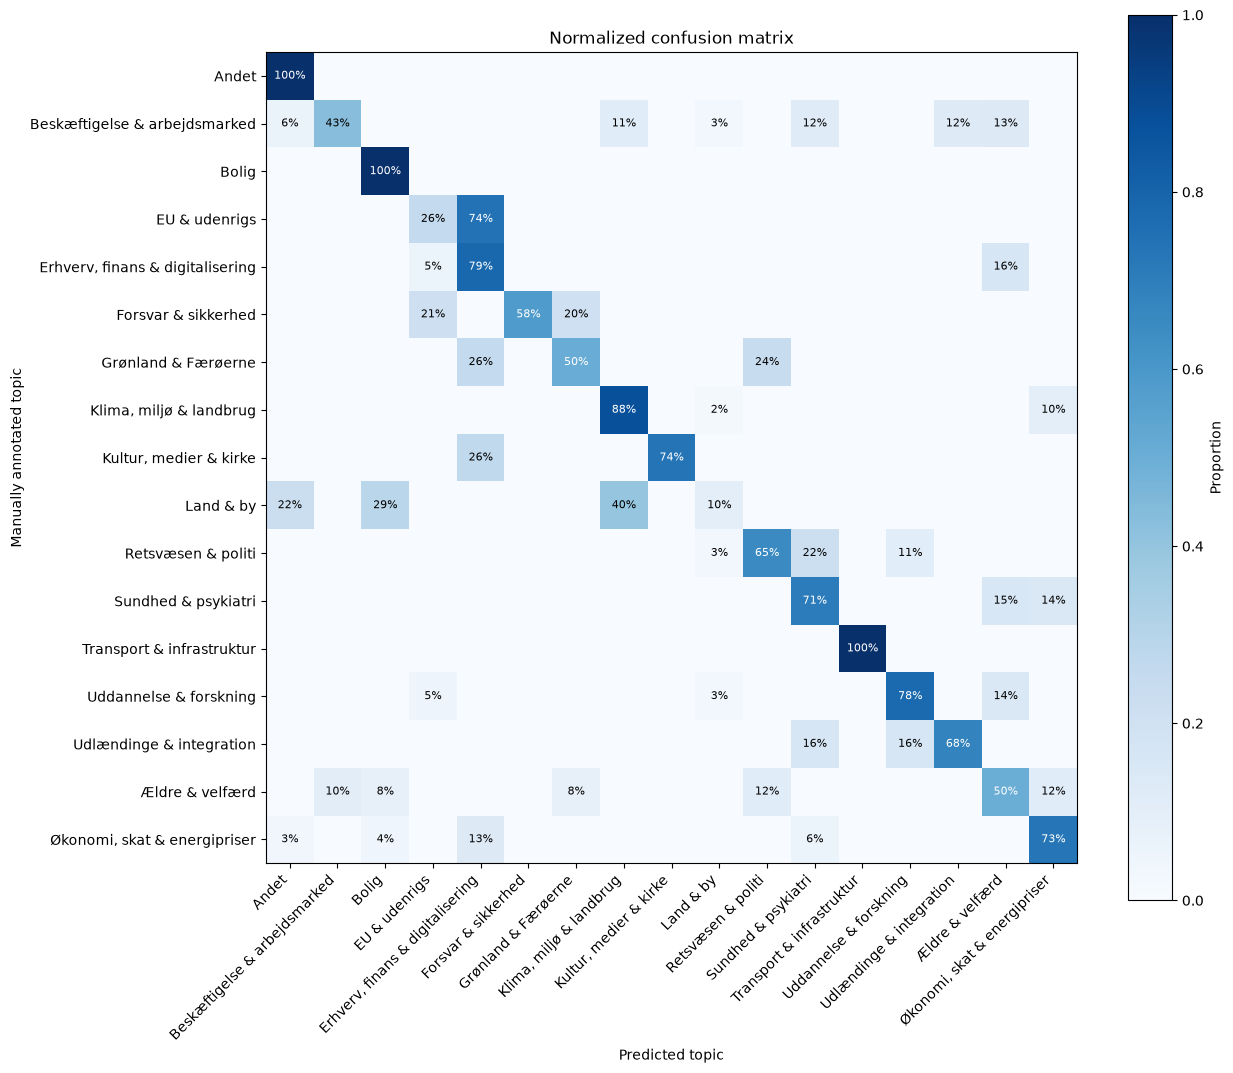

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Precision og recall pr. emnekategori
# ------------------------------------------------------------

plot_data = summary.loc[categories].sort_values("f1-score")

y = np.arange(len(plot_data))
height = 0.35

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    y - height / 2,
    plot_data["precision"],
    height,
    label="Precision",
    color="#4C78A8"
)

ax.barh(
    y + height / 2,
    plot_data["recall"],
    height,
    label="Recall",
    color="#F58518"
)

ax.set_yticks(y)
ax.set_yticklabels([
    f"{category} (n={int(n)})"
    for category, n in zip(
        plot_data.index,
        plot_data["manual_n"]
    )
])

ax.set_xlim(0, 1.05)
ax.set_xlabel("Score")
ax.set_title("Bill topic classification validation")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    OUTPUT / "bill_validation_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 2. Populationsvægtet, normaliseret confusion matrix
# ------------------------------------------------------------

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=categories,
    sample_weight=weights,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(13, 11))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(np.arange(len(categories)))
ax.set_yticks(np.arange(len(categories)))

ax.set_xticklabels(categories, rotation=45, ha="right")
ax.set_yticklabels(categories)

ax.set_xlabel("Predicted topic")
ax.set_ylabel("Manually annotated topic")
ax.set_title("Normalized confusion matrix")

# Tilføj værdier i matricen
for i in range(len(categories)):
    for j in range(len(categories)):
        value = cm_normalized[i, j]

        if value > 0:
            ax.text(
                j, i,
                f"{value:.0%}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value > 0.5 else "black"
            )

fig.colorbar(im, ax=ax, label="Proportion")

fig.tight_layout()

fig.savefig(
    OUTPUT / "bill_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()